In [1]:
!pip install nltk scikit-learn pandas matplotlib seaborn openpyxl

In [2]:
import pandas as pd
import numpy as np
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

In [4]:
uploaded = files.upload()

file_name = list(uploaded.keys())[0]

if file_name.endswith('.csv'):
    df = pd.read_csv(file_name)
elif file_name.endswith(('.xlsx', '.xls')):
    df = pd.read_excel(file_name)
else:
    raise ValueError("Please upload a CSV or Excel file.")

print("Dataset loaded successfully!")

Saving nlp_dataset.csv to nlp_dataset.csv
Dataset loaded successfully!


In [5]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (5937, 2)

Column names:
['Comment', 'Emotion']

First five rows:


,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear



Missing values:
Comment    0
Emotion    0
dtype: int64


In [8]:
print(df.columns.tolist())

['Comment', 'Emotion']


In [9]:
df.columns = df.columns.str.strip()

print("Available columns:", df.columns.tolist())
display(df.head())

Available columns: ['Comment', 'Emotion']


,Comment,Emotion
0,i seriously hate one subject to death but now ...,fear
1,im so full of life i feel appalled,anger
2,i sit here to write i start to dig out my feel...,fear
3,ive been really angry with r and i feel like a...,joy
4,i feel suspicious if there is no one outside l...,fear


In [15]:
print(df.columns.tolist())

['Comment', 'Emotion']


In [16]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)

    tokens = word_tokenize(text)

    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 1
    ]

    return ' '.join(tokens)

TEXT_COLUMN = 'Comment'
LABEL_COLUMN = 'Emotion'

df['Clean_Text'] = df['Comment'].apply(preprocess_text)

display(df[['Comment', 'Clean_Text', 'Emotion']].head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,Comment,Clean_Text,Emotion
0,i seriously hate one subject to death but now ...,seriously hate one subject death feel reluctan...,fear
1,im so full of life i feel appalled,im full life feel appalled,anger
2,i sit here to write i start to dig out my feel...,sit write start dig feelings think afraid acce...,fear
3,ive been really angry with r and i feel like a...,ive really angry feel like idiot trusting firs...,joy
4,i feel suspicious if there is no one outside l...,feel suspicious one outside like rapture happe...,fear


In [17]:
from sklearn.model_selection import train_test_split

X = df['Clean_Text']
y = df['Emotion']

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training data:", len(X_train))
print("Testing data:", len(X_test))

Training data: 4749
Testing data: 1188


In [18]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=10000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF feature extraction completed!")
print("Training shape:", X_train_tfidf.shape)
print("Testing shape:", X_test_tfidf.shape)

TF-IDF feature extraction completed!
Training shape: (4749, 7732)
Testing shape: (1188, 7732)


In [19]:
from sklearn.naive_bayes import MultinomialNB

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

nb_predictions = nb_model.predict(X_test_tfidf)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [20]:
from sklearn.svm import LinearSVC

svm_model = LinearSVC(random_state=42)

svm_model.fit(X_train_tfidf, y_train)

svm_predictions = svm_model.predict(X_test_tfidf)

print("SVM model trained successfully!")

SVM model trained successfully!


In [32]:
import pandas as pd
from sklearn.metrics import (accuracy_score,
    precision_score,
    recall_score,
    f1_score)

results = pd.DataFrame([{'Model': 'Naive Bayes',
        'Accuracy': accuracy_score(y_test, nb_predictions),
        'Precision': precision_score(y_test, nb_predictions,
            average='weighted', zero_division=0),
        'Recall': recall_score(y_test, nb_predictions,
            average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, nb_predictions,
            average='weighted', zero_division=0)},
    {'Model': 'SVM',
        'Accuracy': accuracy_score(y_test, svm_predictions),
        'Precision': precision_score(y_test, svm_predictions,
            average='weighted', zero_division=0),
        'Recall': recall_score(y_test, svm_predictions,
            average='weighted', zero_division=0),
        'F1-Score': f1_score(y_test, svm_predictions,
            average='weighted', zero_division=0)}])

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.8906,0.8915,0.8906,0.8906
1,SVM,0.9411,0.9412,0.9411,0.9410


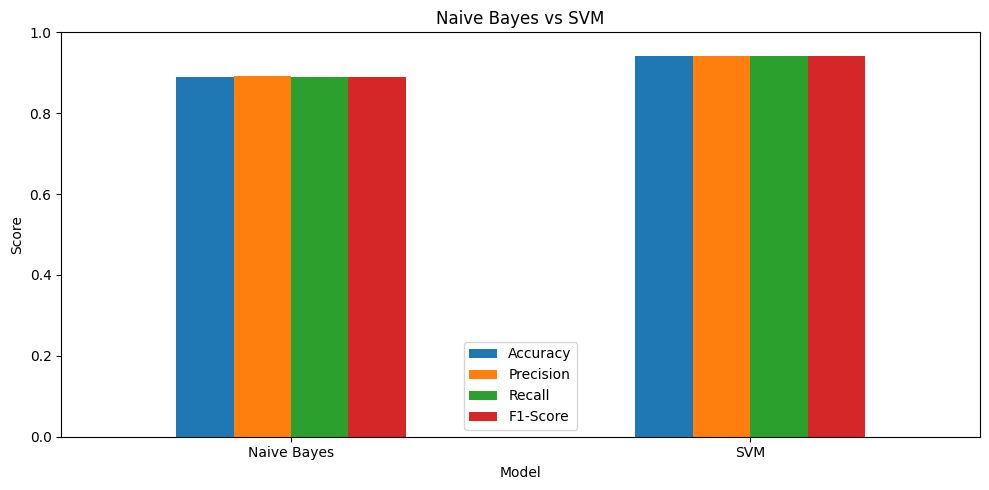

In [33]:
import matplotlib.pyplot as plt

results.set_index('Model').plot(kind='bar',
    figsize=(10, 5))

plt.title('Naive Bayes vs SVM')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import classification_report

print("NAIVE BAYES REPORT")
print(classification_report(y_test, nb_predictions, zero_division=0))

print("\nSVM REPORT")
print(classification_report(y_test, svm_predictions, zero_division=0))

NAIVE BAYES REPORT
              precision    recall  f1-score   support

       anger       0.88      0.91      0.89       400
        fear       0.87      0.90      0.89       388
         joy       0.92      0.86      0.89       400

    accuracy                           0.89      1188
   macro avg       0.89      0.89      0.89      1188
weighted avg       0.89      0.89      0.89      1188


SVM REPORT
              precision    recall  f1-score   support

       anger       0.95      0.93      0.94       400
        fear       0.94      0.93      0.94       388
         joy       0.93      0.96      0.95       400

    accuracy                           0.94      1188
   macro avg       0.94      0.94      0.94      1188
weighted avg       0.94      0.94      0.94      1188



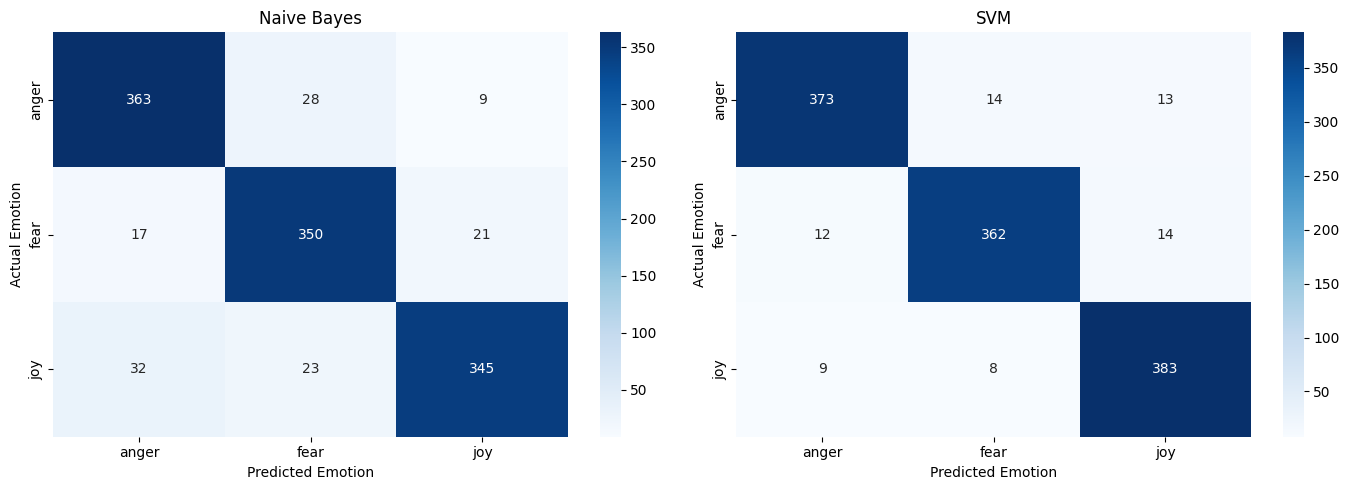

In [35]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, predictions, title in [(axes[0], nb_predictions, 'Naive Bayes'),
    (axes[1], svm_predictions, 'SVM')]:
    cm = confusion_matrix(y_test, predictions, labels=labels)

    sns.heatmap(cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=labels,
        yticklabels=labels,
        ax=ax)

    ax.set_title(title)
    ax.set_xlabel('Predicted Emotion')
    ax.set_ylabel('Actual Emotion')

plt.tight_layout()
plt.show()

In [36]:
best_model_name = results.loc[results['F1-Score'].idxmax(), 'Model']

print("Best model:", best_model_name)

Best model: SVM


In [37]:
best_model = (nb_model
    if best_model_name == 'Naive Bayes'
    else svm_model)

new_comments = ["I am very happy today",
    "I feel sad and lonely",
    "I am angry about this situation"]

cleaned_comments = [preprocess_text(comment)
    for comment in new_comments]

new_features = tfidf.transform(cleaned_comments)

predictions = best_model.predict(new_features)

for comment, emotion in zip(new_comments, predictions):
    print("Comment:", comment)
    print("Predicted Emotion:", emotion)
    print()

Comment: I am very happy today
Predicted Emotion: joy

Comment: I feel sad and lonely
Predicted Emotion: joy

Comment: I am angry about this situation
Predicted Emotion: anger



 Conclusion

In this project, sentiment analysis was performed using machine learning techniques. The text data was preprocessed and converted into numerical features using TF-IDF. Two models, Naive Bayes and Support Vector Machine (SVM), were trained and evaluated using accuracy, precision, recall, and F1-score. Their performance was compared to identify the better-performing model for emotion classification.